# 01 — Exploration des patchs Camelyon17-WILDS

Objectifs : vérifier la correspondance images / étiquettes, mesurer la répartition des classes
et des patientes par hôpital, visualiser des patchs représentatifs et **quantifier les différences
de coloration entre hôpitaux** (changement de domaine).

Données : `data/processed/subset.parquet`, sous-échantillon représentatif tiré des 21 fichiers
(`scripts/fetch_sample.py`). Les conclusions sur les effectifs absolus sont donc à confirmer sur le jeu complet.

In [1]:
import sys; sys.path.insert(0, '..')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from skimage.color import rgb2hed, rgb2hsv
from src.data import load_parquet, assign_splits, decode

FIG = Path('../reports/figures'); FIG.mkdir(parents=True, exist_ok=True)
CENTER_NAME = {0: 'C0 (train)', 1: 'C1 (val OOD)', 2: 'C2 (test OOD)', 3: 'C3 (train)', 4: 'C4 (train)'}
df = assign_splits(load_parquet(['../data/processed/subset.parquet']))
print(f'{len(df)} patchs, {df.patient_id.nunique()} patientes, {df.slide_id.nunique()} lames')

40254 patchs, 43 patientes, 50 lames


## 1. Correspondance images / étiquettes et format

In [2]:
shapes = pd.Series([decode(b).shape for b in df.img.sample(500, random_state=0)]).value_counts()
print('Formats observés :', shapes.to_dict())
print('Valeurs manquantes :', int(df.drop(columns='img').isna().sum().sum()))
print('Étiquettes :', df.label.value_counts().to_dict())

Formats observés : {(96, 96, 3): 500}
Valeurs manquantes : 0
Étiquettes : {0: 20264, 1: 19990}


## 2. Répartition par hôpital, patiente et classe

In [3]:
summary = df.groupby('center').agg(patchs=('label', 'size'), part_tumeur=('label', 'mean'),
                                   patientes=('patient_id', 'nunique'), lames=('slide_id', 'nunique'))
summary.index = summary.index.map(CENTER_NAME)
summary.round(3)

,patchs,part_tumeur,patientes,lames
center,,,,
C0 (train),5101,0.489,7,10
C1 (val OOD),2942,0.483,8,10
C2 (test OOD),7854,0.500,9,10
C3 (train),11506,0.499,10,10
C4 (train),12851,0.499,9,10


In [4]:
split_tab = pd.crosstab(df.split, df.label, margins=True).rename(columns={0: 'non tumoral', 1: 'tumoral'})
split_tab['patientes'] = df.groupby('split').patient_id.nunique()
split_tab

label,non tumoral,tumoral,All,patientes
split,,,,
test_ood,3927,3927,7854,9.0
train,11418,13343,24761,21.0
val_id,3398,1299,4697,5.0
val_ood,1521,1421,2942,8.0
All,20264,19990,40254,NaN


**À retenir.** WILDS a été construit **équilibré** (environ autant de patchs tumoraux que non tumoraux).
Ce n'est pas la réalité clinique : sur une lame entière, le tissu tumoral représente souvent moins de 1 %
de la surface. Le déséquilibre se posera donc surtout au niveau des lames (semaine 3) et lors du choix du seuil.

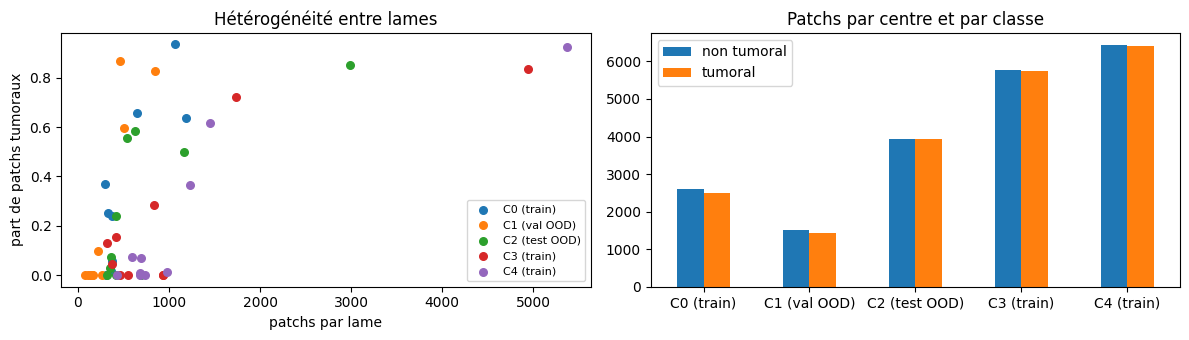

In [5]:
per_slide = df.groupby(['center', 'slide_id']).agg(n=('label', 'size'), tumeur=('label', 'mean')).reset_index()
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for c, g in per_slide.groupby('center'):
    ax[0].scatter(g.n, g.tumeur, label=CENTER_NAME[c], s=30)
ax[0].set(xlabel='patchs par lame', ylabel='part de patchs tumoraux', title='Hétérogénéité entre lames'); ax[0].legend(fontsize=8)
pd.crosstab(df.center.map(CENTER_NAME), df.label).plot.bar(ax=ax[1], rot=0)
ax[1].set(title='Patchs par centre et par classe', xlabel=''); ax[1].legend(['non tumoral', 'tumoral'])
plt.tight_layout(); plt.savefig(FIG / 'repartition.png', dpi=150)

## 3. Patchs représentatifs par classe et par hôpital

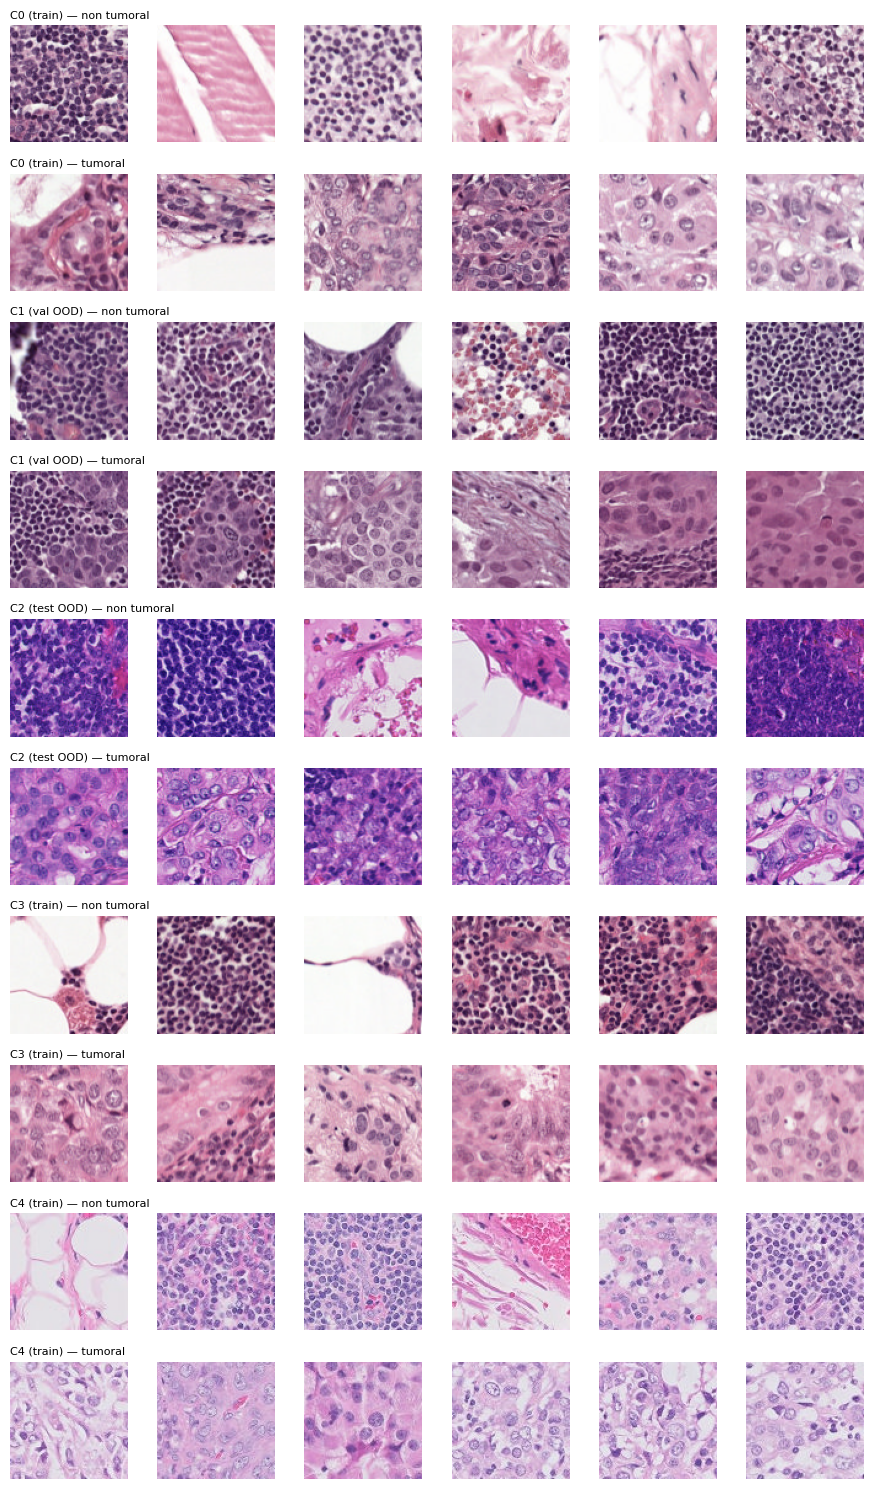

In [6]:
fig, axes = plt.subplots(10, 6, figsize=(9, 15))
for i, c in enumerate(range(5)):
    for j, lab in enumerate((0, 1)):
        g = df[(df.center == c) & (df.label == lab)]
        sample = g.sample(min(6, len(g)), random_state=1)
        for k in range(6):
            a = axes[2 * i + j, k]; a.axis('off')
            if k < len(sample):
                a.imshow(decode(sample.img.iloc[k]))
        axes[2 * i + j, 0].set_title(f"{CENTER_NAME[c]} — {'tumoral' if lab else 'non tumoral'}", loc='left', fontsize=8)
plt.tight_layout(); plt.savefig(FIG / 'galerie.png', dpi=150)

**Observations.** Les patchs tumoraux montrent des cellules plus grandes, aux noyaux volumineux et clairs
avec nucléoles ; les patchs non tumoraux sont surtout des nappes de lymphocytes (petits noyaux ronds et sombres),
de la graisse (grands vides blancs) ou du stroma rose. **La teinte varie fortement d'un hôpital à l'autre** :
le centre 2 (test) est nettement plus violet et saturé, le centre 4 plus pâle, les centres 0, 1 et 3 plus roses.

## 4. Coloration : quantifier le changement de domaine

In [7]:
rng = np.random.default_rng(0)
samp = df.groupby(['center', 'label'], group_keys=False).apply(lambda g: g.sample(min(len(g), 400), random_state=0))
def color_stats(png):
    rgb = decode(png); hsv = rgb2hsv(rgb); hed = rgb2hed(rgb)
    return [*rgb.reshape(-1, 3).mean(0), hsv[..., 1].mean(), hed[..., 0].mean(), hed[..., 1].mean()]
cols = ['R', 'G', 'B', 'saturation', 'hematoxyline', 'eosine']
stats = pd.DataFrame([color_stats(b) for b in samp.img], columns=cols, index=samp.index)
stats[['center', 'label']] = samp[['center', 'label']]
stats.groupby(['center', 'label'])[cols].mean().round(3)

R        G        B  saturation  hematoxyline  eosine
center label                                                             
0      0      189.127  157.734  180.185       0.207         0.035   0.009
       1      186.489  150.842  177.735       0.214         0.026   0.010
1      0      150.281  119.878  150.366       0.277         0.053   0.011
       1      161.340  116.980  153.288       0.305         0.039   0.016
2      0      172.225  127.028  187.285       0.386         0.047   0.027
       1      169.803  115.241  188.627       0.412         0.043   0.029
3      0      163.626  122.132  153.064       0.318         0.049   0.017
       1      185.924  127.333  162.645       0.335         0.022   0.021
4      0      200.115  166.997  205.943       0.218         0.024   0.011
       1      208.285  177.904  213.010       0.178         0.019   0.010

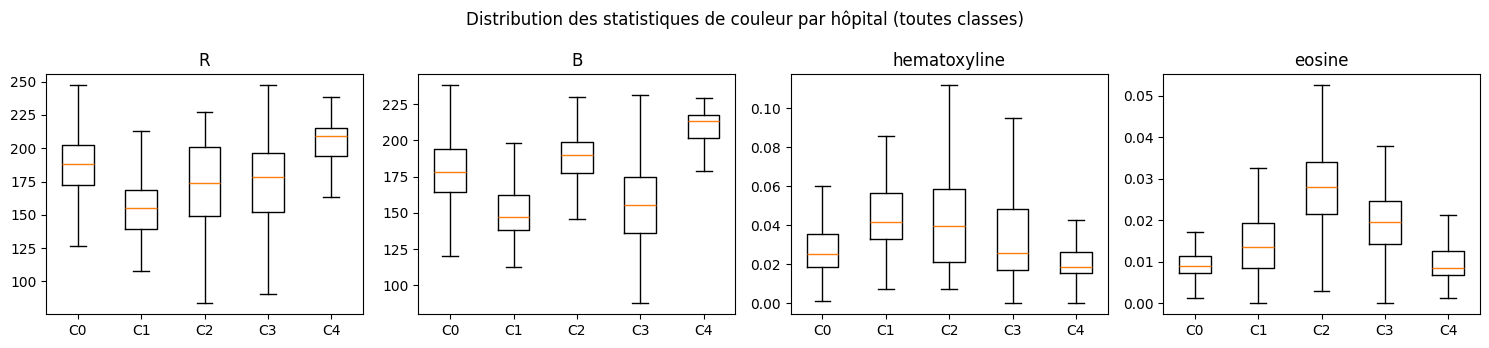

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.5))
for a, col in zip(axes, ['R', 'B', 'hematoxyline', 'eosine']):
    data = [stats.loc[stats.center == c, col] for c in range(5)]
    a.boxplot(data, tick_labels=[CENTER_NAME[c].split()[0] for c in range(5)], showfliers=False); a.set_title(col)
plt.suptitle('Distribution des statistiques de couleur par hôpital (toutes classes)'); plt.tight_layout()
plt.savefig(FIG / 'couleur_par_centre.png', dpi=150)

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
X = stats[cols].values
acc_center = cross_val_score(make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)), X, stats.center, cv=5).mean()
acc_label = cross_val_score(make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)), X, stats.label, cv=5).mean()
print(f"Avec 6 statistiques de couleur : centre prédit à {acc_center:.1%} (hasard 20 %), classe prédite à {acc_label:.1%} (hasard ~50 %)")

Avec 6 statistiques de couleur : centre prédit à 80.2% (hasard 20 %), classe prédite à 68.2% (hasard ~50 %)


**Résultat.** Avec 6 nombres de couleur, l'hôpital est reconnu dans environ 80 % des cas (hasard : 20 %),
et la projection t-SNE sépare nettement les centres 2 et 4 des centres 0, 1 et 3. Le centre 2, réservé au test,
a une coloration que l'on ne voit dans aucun centre d'entraînement sauf en partie le centre 4.

Si la couleur seule permet de reconnaître l'hôpital bien mieux que le hasard, un modèle peut apprendre
des raccourcis liés à la coloration plutôt qu'à la morphologie. C'est l'argument pour la normalisation ou
l'augmentation de couleur (HED), testées en semaine 2, et pour évaluer sur des hôpitaux jamais vus (C1, C2).

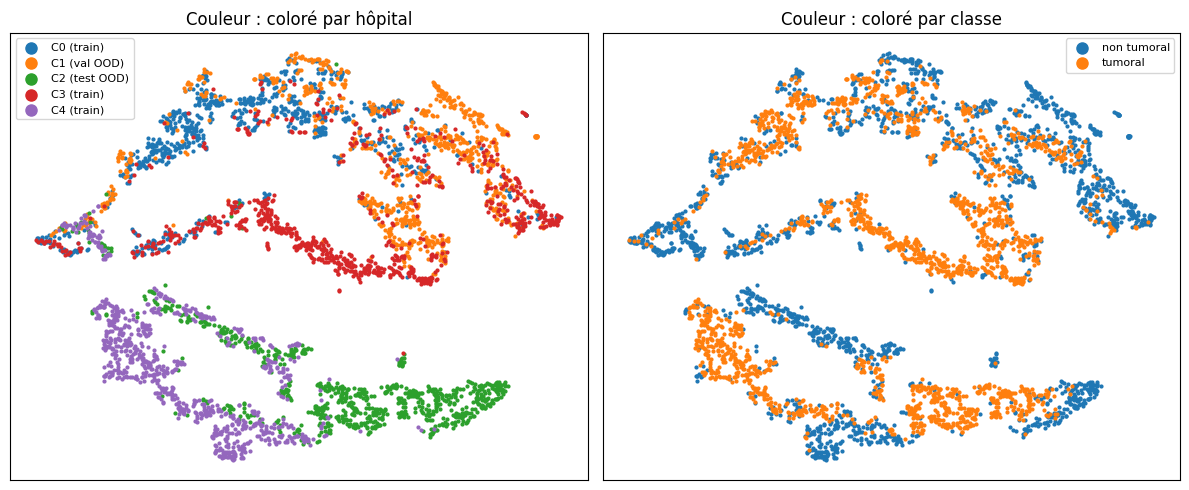

In [10]:
from sklearn.manifold import TSNE
emb = TSNE(random_state=0, init='pca', perplexity=40).fit_transform((X - X.mean(0)) / X.std(0))
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for c in range(5):
    m = stats.center.values == c; ax[0].scatter(*emb[m].T, s=4, label=CENTER_NAME[c])
for lab, name in ((0, 'non tumoral'), (1, 'tumoral')):
    m = stats.label.values == lab; ax[1].scatter(*emb[m].T, s=4, label=name)
ax[0].set_title('Couleur : coloré par hôpital'); ax[1].set_title('Couleur : coloré par classe')
for a in ax: a.legend(markerscale=4, fontsize=8); a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.savefig(FIG / 'tsne_couleur.png', dpi=150)

## 5. Position des patchs dans une lame

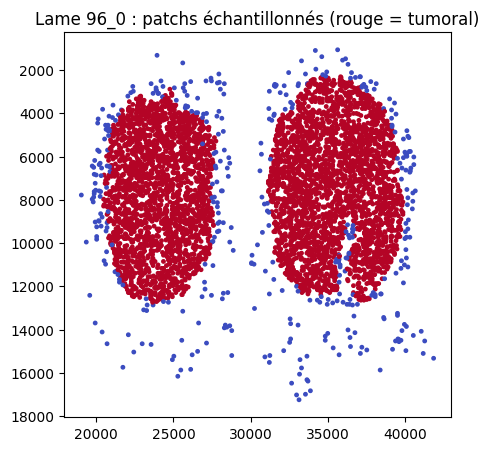

In [11]:
slide = per_slide.sort_values('n').iloc[-1].slide_id
g = df[df.slide_id == slide]
plt.figure(figsize=(5, 5)); plt.scatter(g.x_coord, g.y_coord, c=g.label, cmap='coolwarm', s=6)
plt.gca().invert_yaxis(); plt.title(f'Lame {slide} : patchs échantillonnés (rouge = tumoral)')
plt.savefig(FIG / 'positions_lame.png', dpi=150)

Les patchs tumoraux sont **spatialement regroupés** : deux patchs voisins d'une même lame se ressemblent
beaucoup. C'est pourquoi un découpage aléatoire par patch gonflerait artificiellement les scores ;
on découpe par patiente (`assign_splits`) et on vérifie l'absence de fuite.

## 6. Synthèse pour la suite

1. Format homogène (96×96 RGB), étiquettes binaires, aucune valeur manquante.
2. Jeu de patchs équilibré par construction : le vrai déséquilibre apparaîtra au niveau lame.
3. Forte variabilité de couleur entre hôpitaux : à traiter (HED, normalisation) et à évaluer hors domaine.
4. Patchs spatialement corrélés : découpage par patiente obligatoire.